# Axis 2 — Eviction Policy & Expert Locality (Mac / MLX)

**Model:** `OLMoE-1B-7B-0125-Instruct` (MLX, F16)  
**Architecture:** 16 layers × 64 experts/layer × top-8 routing = **1,024 logical experts**  
**Platform:** Apple Silicon, MLX

## Research question
Does expert routing exhibit strong enough temporal / spatial locality to justify complex
eviction logic over simple FIFO / LRU?

## Hypothesis
- **H1:** LFU beats LRU on homogeneous, sustained tasks, because it pins frequently used core
  ("syntactic") experts instead of letting them age out.
- **H2:** Across multi-turn domain shifts, un-decayed LFU keeps stale experts from the previous
  domain, so its hit rate falls *below* LRU (and a decayed LFU should recover).

## Design

This notebook studies **cache residency** only; storage, routing and computation are separate:

1. **Storage** — per-expert tensors stay on disk. A byte-range index is built from the
   safetensors headers; nothing is loaded.
2. **Residency** — a *global* cache keyed by `(layer, expert_id)` with capacity `K`.
   At most `K` experts are resident across all 16 layers at any time. `K=1024` is the full bank.
3. **Routing** — greedy generation with **exact expert weights paged from disk**, so the router
   sees real activations and records the model's authentic routing. (Zeroing expert weights, as
   an earlier prototype did, corrupts the residual stream and therefore the routing itself.)
4. **Replay** — the recorded access stream is replayed against FIFO / LRU / LFU / decayed-LFU.
   The simulator is validated against a real disk-backed cache: same requests, same counters.

### What counts as an access?

A real MoE layer loads each **distinct** expert once per call and shares it across the batch.
So the trace is recorded at **call granularity**: for every MoE call (layer, token batch), the
set of distinct experts actually fetched, in fetch order. Counting one "request" per token
instead would inflate hit rates with within-batch reuse that costs no I/O and no eviction.

In [1]:
import gc, json, struct, time, platform
from collections import Counter, OrderedDict, deque
from pathlib import Path
from heapq import heappush, heappop

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import psutil

import mlx.core as mx
import mlx.nn as nn
from safetensors import safe_open
from mlx_lm.utils import load_config, _get_classes
from mlx_lm.tokenizer_utils import load as load_tokenizer
from mlx_lm.generate import generate_step

assert platform.system() == 'Darwin', 'This notebook targets macOS / Apple Silicon.'

sns.set_style('whitegrid')
plt.rcParams.update({'figure.figsize': (12, 6), 'font.size': 10})
print('Imports OK | mlx', mx.__version__)

Imports OK | mlx 0.32.2


## Configuration

`K` is **global** (all layers). Per-layer capacity is `K / 16` on average; the label below shows
the equivalent. Capacities are powers of two so they line up with per-layer values.

`TRACE_CACHE_K` is the capacity of the disk cache used only to reproduce activations while
tracing. It changes I/O time, never routing correctness (weights are exact either way).

In [2]:
CWD = Path.cwd()
if CWD.name == 'axis-2-eviction-policies':
    EXP_DIR = CWD
    MODEL_DIR = CWD.parent.parent / 'models' / 'OLMoE-1B-7B-0125-Instruct'
else:
    EXP_DIR = CWD / 'experiments' / 'axis-2-eviction-policies'
    MODEL_DIR = CWD / 'models' / 'OLMoE-1B-7B-0125-Instruct'

assert MODEL_DIR.exists(), f'Model not found: {MODEL_DIR}'
TRACE_DIR = EXP_DIR / 'traces'
TRACE_DIR.mkdir(exist_ok=True)

NUM_LAYERS = 16
NUM_EXPERTS_PER_LAYER = 64
TOP_K = 8
TOTAL_EXPERTS = NUM_LAYERS * NUM_EXPERTS_PER_LAYER         # 1,024

# Global cache capacities to test. 1024 = full bank -> sanity check (no evictions).
GLOBAL_K_VALUES = [128, 256, 512, 1024]

# Policy name -> extra kwargs (LFU half-life in accesses; None = no decay).
POLICY_CONFIGS = {
    'FIFO':      {},
    'LRU':       {},
    'LFU':       {},
    'LFU-H256':  {'half_life': 256.0},
    'LFU-H1024': {'half_life': 1024.0},
}

TRACE_CACHE_K = 512        # disk-cache capacity used while tracing only
MAX_NEW_TOKENS = 24        # generated tokens per prompt
POST_SHIFT_WINDOW = 2048   # decode accesses (~16 generated tokens) after a domain switch
ROLLING_WINDOW = 512       # window for hit-rate-over-time curves
RUN_REAL_CACHE_VALIDATION = True
VALIDATION_K = 128
REUSE_TRACES = True        # reuse saved traces when prompts/config are unchanged

print(f'Model dir: {MODEL_DIR}')
print(f'Architecture: {NUM_LAYERS} layers x {NUM_EXPERTS_PER_LAYER} experts x top-{TOP_K}')
print(f'Global K values: {GLOBAL_K_VALUES}  (per-layer equivalents: '
      f'{[k // NUM_LAYERS for k in GLOBAL_K_VALUES]})')
print(f'Tracing cache: K={TRACE_CACHE_K} (tracing only)')
print(f'Policies: {list(POLICY_CONFIGS)}')

Model dir: /Users/falak/Documents/Falak/College/Sem - 3/DS635/MoE - Inference System/models/OLMoE-1B-7B-0125-Instruct
Architecture: 16 layers x 64 experts x top-8
Global K values: [128, 256, 512, 1024]  (per-layer equivalents: [8, 16, 32, 64])
Tracing cache: K=512 (tracing only)
Policies: ['FIFO', 'LRU', 'LFU', 'LFU-H256', 'LFU-H1024']


In [3]:
SUSTAINED_PROMPTS = [
    'Write a Python function to implement binary search.',
    'Explain how recursion works in programming.',
    'What is the difference between a list and a tuple in Python?',
    'Write a function to sort an array using quicksort.',
    'Explain the concept of Big O notation.',
]

DOMAIN_SHIFT_PROMPTS = [
    # Segment 1 — programming
    'Write a JavaScript function to validate email addresses.',
    'Explain the difference between let and const in JavaScript.',
    'What is a closure in JavaScript?',
    # Segment 2 — creative writing (shift)
    'Write a short story about a robot learning to paint.',
    'Describe the sunset over the ocean in vivid detail.',
    'Write a poem about the changing seasons.',
    # Segment 3 — technical (shift)
    'Explain how neural networks process images.',
    'What is the difference between CPU and GPU?',
    'Describe how machine learning models are trained.',
]

WORKLOADS = {
    'sustained': {
        'prompts': SUSTAINED_PROMPTS,
        'segments': ['programming'] * len(SUSTAINED_PROMPTS),
    },
    'domain_shift': {
        'prompts': DOMAIN_SHIFT_PROMPTS,
        'segments': ['programming'] * 3 + ['creative'] * 3 + ['technical'] * 3,
    },
}

for name, w in WORKLOADS.items():
    print(f'{name}: {len(w["prompts"])} prompts, segments={Counter(w["segments"])}')

sustained: 5 prompts, segments=Counter({'programming': 5})
domain_shift: 9 prompts, segments=Counter({'programming': 3, 'creative': 3, 'technical': 3})


## Step 1 — Build a byte-range index of the expert bank

Only safetensors headers (a few KB) are read. Each expert projection
(`gate_proj`, `up_proj`, `down_proj`) gets a `(file, offset, nbytes)` entry, so a cache miss can
read exactly that expert's bytes. Nothing from the expert bank is loaded here.

In [4]:
def parse_safetensors_header(filepath):
    '''Read only the JSON header of a safetensors file (no tensor data).'''
    with open(filepath, 'rb') as f:
        header_size = struct.unpack('<Q', f.read(8))[0]
        header_json = json.loads(f.read(header_size))
    return header_size, header_json

PROJECTIONS = ('gate_proj', 'up_proj', 'down_proj')
expert_index = {}              # (layer, expert_id, proj) -> disk location
non_expert_keys_by_shard = {}  # shard path -> [non-expert tensor names]

shard_files = sorted(MODEL_DIR.glob('model*.safetensors'))
if not shard_files:
    raise FileNotFoundError(f'No model*.safetensors in {MODEL_DIR}')

for shard in shard_files:
    header_size, meta = parse_safetensors_header(shard)
    data_start = 8 + header_size
    ne_keys = []
    for name, info in meta.items():
        if name == '__metadata__':
            continue
        if '.mlp.experts.' in name and name.endswith('.weight'):
            parts = name.split('.')
            expert_index[(int(parts[2]), int(parts[5]), parts[6])] = {
                'file': str(shard),
                'data_start': data_start + info['data_offsets'][0],
                'nbytes': info['data_offsets'][1] - info['data_offsets'][0],
                'shape': tuple(info['shape']),
                'dtype': info['dtype'],
            }
        else:
            ne_keys.append(name)   # attention, norms, router (gate), lm_head
    non_expert_keys_by_shard[str(shard)] = ne_keys

EXPERT_BYTES = sum(expert_index[(0, 0, p)]['nbytes'] for p in PROJECTIONS)
n_entries = len(expert_index)

print(f'Expert index entries: {n_entries} (expected {TOTAL_EXPERTS * 3})')
print(f'Non-expert tensors: {sum(len(v) for v in non_expert_keys_by_shard.values())}')
print(f'Bytes per expert (3 projections): {EXPERT_BYTES / 1e6:.2f} MB')
print(f'Full expert bank: {EXPERT_BYTES * TOTAL_EXPERTS / 1e9:.1f} GB')
print(f'Example: layer 0 / expert 0 / gate_proj -> shape '
      f'{expert_index[(0, 0, "gate_proj")]["shape"]}, '
      f'{expert_index[(0, 0, "gate_proj")]["nbytes"] / 1e6:.1f} MB')

Expert index entries: 3072 (expected 3072)
Non-expert tensors: 147
Bytes per expert (3 projections): 12.58 MB
Full expert bank: 12.9 GB
Example: layer 0 / expert 0 / gate_proj -> shape (1024, 2048), 4.2 MB


## Step 2 — Eviction policies (simulation core)

All policies implement `access(key) -> (hit, evicted_key)` and never hold more than `capacity`
keys. They are used twice:

* by the **replay simulator** (keys only), and
* by the **real disk-backed cache** (keys + weights, so `evicted_key` tells us what to free).

LFU keeps `(frequency, last_access_time)` per key and evicts the entry with the smallest
**decayed** frequency. Decay is lazy: at time `t`, the decayed frequency is
`f · 2^(-(t - t_last)/H)`, and comparing entries at a fixed `t` reduces to
`f · 2^(t_last/H)`, so no scan over the cache is needed. A min-heap with lazy invalidation makes
updates and evictions `O(log n)`; `LFU` is simply `H = ∞` (no decay).

In [5]:
class FIFOPolicy:
    def __init__(self, capacity):
        self.capacity = max(1, int(capacity))
        self._q = deque()
        self._set = set()
        self.hits = self.misses = self.evictions = 0

    def __len__(self):
        return len(self._set)

    def access(self, key):
        if key in self._set:
            self.hits += 1
            return True, None
        self.misses += 1
        evicted = None
        if len(self._set) >= self.capacity:
            evicted = self._q.popleft()
            self._set.discard(evicted)
            self.evictions += 1
        self._q.append(key)
        self._set.add(key)
        return False, evicted


class LRUPolicy:
    def __init__(self, capacity):
        self.capacity = max(1, int(capacity))
        self._od = OrderedDict()
        self.hits = self.misses = self.evictions = 0

    def __len__(self):
        return len(self._od)

    def access(self, key):
        if key in self._od:
            self.hits += 1
            self._od.move_to_end(key)
            return True, None
        self.misses += 1
        evicted = None
        if len(self._od) >= self.capacity:
            evicted, _ = self._od.popitem(last=False)
            self.evictions += 1
        self._od[key] = None
        return False, evicted


class LFUPolicy:
    '''LFU with optional exponential decay (half-life in accesses).'''

    def __init__(self, capacity, half_life=None):
        self.capacity = max(1, int(capacity))
        self.half_life = None if half_life is None else float(half_life)
        self._freq = {}    # key -> [count_at_last_access, last_access_time]
        self._ver = {}     # key -> monotonically increasing version (lazy invalidation)
        self._next_ver = 0
        self._heap = []
        self._t = 0
        self.hits = self.misses = self.evictions = 0

    def __len__(self):
        return len(self._freq)

    def _score(self, key):
        f, t_last = self._freq[key]
        if self.half_life is None:
            return (f, t_last)
        return (f * (2.0 ** (t_last / self.half_life)), t_last)

    def _push(self, key):
        self._ver[key] = self._next_ver
        self._next_ver += 1
        heappush(self._heap, (*self._score(key), key, self._ver[key]))

    def _evict_one(self):
        while self._heap:
            _, _, key, ver = heappop(self._heap)
            if key in self._freq and self._ver.get(key) == ver:
                del self._freq[key]
                self._ver.pop(key, None)
                self.evictions += 1
                return key
        return None

    def access(self, key):
        self._t += 1
        if key in self._freq:
            self.hits += 1
            self._freq[key][0] += 1
            self._freq[key][1] = self._t
            self._push(key)
            return True, None

        self.misses += 1
        evicted = None
        if len(self._freq) >= self.capacity:
            evicted = self._evict_one()
        self._freq[key] = [1.0, self._t]
        self._push(key)
        return False, evicted


def make_policy(name, capacity):
    if name == 'FIFO':
        return FIFOPolicy(capacity)
    if name == 'LRU':
        return LRUPolicy(capacity)
    return LFUPolicy(capacity, half_life=POLICY_CONFIGS[name].get('half_life'))


# ── Self-test: heap-based LFU vs the same eviction rule via linear scan ──
# Comparing f*2^(t_last/H) at a fixed time is equivalent to comparing the lazy
# decayed frequency f*2^(-(t-t_last)/H); the scan checks heap/lazy-invalidation.
def _scan_lfu(seq, capacity, half_life=None):
    cache = {}          # key -> [frequency_at_last_access, last_access_time]
    hits = misses = evictions = 0
    for t, key in enumerate(seq, start=1):
        if key in cache:
            hits += 1
            cache[key][0] += 1
            cache[key][1] = t
            continue
        misses += 1
        if len(cache) >= capacity:
            def priority(k):
                f, tl = cache[k]
                if half_life is None:
                    return (f, tl, k)
                return (f * 2.0 ** (tl / half_life), tl, k)
            del cache[min(cache, key=priority)]
            evictions += 1
        cache[key] = [1.0, t]
    return hits, misses, evictions


rng = np.random.default_rng(0)
for _ in range(40):
    seq = [int(x) for x in rng.integers(0, 12, size=250)]
    cap = int(rng.integers(1, 7))
    for hl in (None, 7.0, 30.0):
        pol = LFUPolicy(cap, half_life=hl)
        for k in seq:
            pol.access(k)
        ref = _scan_lfu(seq, cap, half_life=hl)
        assert (pol.hits, pol.misses, pol.evictions) == ref, (hl, cap, pol.hits, ref)
        assert len(pol) <= cap

print('Policies ready: FIFO, LRU, LFU, decayed LFU. LFU matches the scan reference.')

Policies ready: FIFO, LRU, LFU, decayed LFU. LFU matches the scan reference.


## Step 3 — Disk-backed global expert cache + model

Only **non-expert** weights (attention, norms, router, embeddings, head) are loaded — about
1 GB. The randomly initialised expert bank is zeroed *before* loading so it is never
materialised. `switch_mlp` on every layer is then replaced by a view onto one **global**
`DiskExpertCache`, whose policy and capacity are the knobs under study.

The view reproduces `SwitchGLU`: `down(silu(x·Wg) * (x·Wu))`, batched by distinct expert.
It also reports the exact fetch order, which becomes the trace.

In [6]:
class DiskExpertCache:
    '''Global cache over (layer, expert_id). Weights stay on disk; at most K are resident.'''

    def __init__(self, expert_index, capacity, policy_name='LRU'):
        self.expert_index = expert_index
        self.policy = make_policy(policy_name, capacity)
        self.weights = {}
        self.bytes_loaded = 0
        self.io_ms = 0.0
        self.ms_per_load = []

    def _read_proj(self, layer, eid, proj):
        ie = self.expert_index[(layer, eid, proj)]
        with open(ie['file'], 'rb') as f:
            f.seek(ie['data_start'])
            raw = f.read(ie['nbytes'])
        return mx.array(np.frombuffer(raw, dtype=np.float16).reshape(ie['shape']))

    def get(self, layer, eid):
        key = (layer, eid)
        hit, evicted = self.policy.access(key)
        if evicted is not None:
            self.weights.pop(evicted, None)
        if hit:
            return self.weights[key]

        t0 = time.perf_counter()
        w = tuple(self._read_proj(layer, eid, p) for p in PROJECTIONS)
        mx.eval(*w)                      # force real I/O + upload before timing
        dt = (time.perf_counter() - t0) * 1000
        self.io_ms += dt
        self.ms_per_load.append(dt)
        self.bytes_loaded += sum(self.expert_index[(layer, eid, p)]['nbytes']
                                 for p in PROJECTIONS)
        self.weights[key] = w
        return w

    @property
    def capacity(self):
        return self.policy.capacity

    def __len__(self):
        return len(self.policy)

    def resident_bytes(self):
        return sum(a.nbytes for w in self.weights.values() for a in w)

    def summary(self):
        total = self.policy.hits + self.policy.misses
        return {
            'accesses': total,
            'hits': self.policy.hits,
            'misses': self.policy.misses,
            'hit_rate': self.policy.hits / total if total else float('nan'),
            'evictions': self.policy.evictions,
            'resident': len(self.policy),
            'resident_MB': self.resident_bytes() / 1e6,
            'MB_loaded': self.bytes_loaded / 1e6,
            'io_ms': self.io_ms,
        }


class ExpertCacheLayerView:
    '''Drop-in replacement for SwitchGLU that serves exact weights from a DiskExpertCache.'''

    def __init__(self, store, layer, observer=None):
        self.store = store
        self.layer = layer
        self.observer = observer

    def __call__(self, x, indices):
        N, k = indices.shape
        rows = indices.tolist()

        if N == 1:                                   # decode: one token, slot order
            eids = [int(e) for e in rows[0]]
            if self.observer:
                self.observer(self.layer, eids, N)
            out = []
            for eid in eids:
                gw, uw, dw = self.store.get(self.layer, eid)
                out.append((nn.silu(x @ gw.T) * (x @ uw.T)) @ dw.T)
            return mx.stack(out, axis=1)

        # prefill: group tokens by distinct expert, fetch in ascending expert order
        emap = {}
        for t, row in enumerate(rows):
            for slot, e in enumerate(row):
                emap.setdefault(int(e), []).append((t, slot))
        eids = sorted(emap)
        if self.observer:
            self.observer(self.layer, eids, N)

        y = [[None] * k for _ in range(N)]
        for eid in eids:
            gw, uw, dw = self.store.get(self.layer, eid)
            pos = emap[eid]
            xt = x[[t for t, _ in pos]]
            out = (nn.silu(xt @ gw.T) * (xt @ uw.T)) @ dw.T
            for i, (t, slot) in enumerate(pos):
                y[t][slot] = out[i]
        return mx.stack([mx.stack(row) for row in y])


def install_cache(model, store, observer=None):
    for i, layer in enumerate(model.model.layers):
        layer.mlp.switch_mlp = ExpertCacheLayerView(store, i, observer)


# ── Load non-expert weights, keep the expert bank on disk ──
print('Loading config / tokenizer / model skeleton...')
config = load_config(MODEL_DIR)
tokenizer = load_tokenizer(MODEL_DIR)
model_class, model_args_class = _get_classes(config)
model = model_class(model_args_class.from_dict(config))

# Zero the random expert bank BEFORE anything is evaluated.
for layer in model.model.layers:
    sw = layer.mlp.switch_mlp
    for proj in PROJECTIONS:
        getattr(sw, proj).weight = mx.zeros((1, 1, 1))
gc.collect(); mx.clear_cache()

t0 = time.perf_counter()
for shard in shard_files:
    keys = non_expert_keys_by_shard[str(shard)]
    if not keys:
        continue
    with safe_open(shard, framework='numpy') as f:
        weights = {k: mx.array(f.get_tensor(k)) for k in keys}
    model.load_weights(list(weights.items()), strict=False)
    del weights
gc.collect()

print(f'Non-expert weights loaded in {time.perf_counter() - t0:.1f}s')
print(f'Router gate shape: {model.model.layers[0].mlp.gate["weight"].shape}')
print(f'Active Metal memory: {mx.get_active_memory() / 1e9:.2f} GB '
      f'(full bank would be {EXPERT_BYTES * TOTAL_EXPERTS / 1e9:.1f} GB)')

Loading config / tokenizer / model skeleton...
Non-expert weights loaded in 1.8s
Router gate shape: (64, 2048)
Active Metal memory: 0.95 GB (full bank would be 12.9 GB)


## Step 4 — Record the access stream from real generation

For each prompt we sweep a fresh disk cache with a recording observer and greedy generation.
Fresh state per prompt only bounds memory; the **simulated** cache state is carried across the
whole workload, which is what the policy comparison needs.

Each record is a MoE call: `(layer, prompt, token_start, distinct experts fetched)`. Sorting by
call order reproduces the exact sequence in which a real cache would be asked for experts
(layer-major during prefill, token-major during decode).

Traces are cached in `traces/*.json`; delete those files or set `REUSE_TRACES=False` to
re-collect.

In [7]:
class AccessRecorder:
    '''Records one event per MoE call, with the distinct experts fetched.'''

    def __init__(self):
        self.events = []
        self.pos = 0          # token position within the current prompt
        self.prompt_id = 0
        self._start = 0

    def begin_prompt(self, prompt_id):
        self.prompt_id = prompt_id
        self.pos = 0

    def __call__(self, layer, eids, n_tokens):
        if layer == 0:                 # layer 0 runs first in every forward pass
            self._start = self.pos
            self.pos += n_tokens
        self.events.append({
            'call': len(self.events),
            'layer': int(layer),
            'start': int(self._start),
            'n': int(n_tokens),
            'prompt': int(self.prompt_id),
            'eids': [int(e) for e in eids],
        })


def run_prompt_with_trace(prompt, prompt_id, capacity=TRACE_CACHE_K,
                          policy_name='LRU', max_new_tokens=MAX_NEW_TOKENS):
    '''Greedy generation with real experts paged from disk; returns trace + real cache stats.'''
    store = DiskExpertCache(expert_index, capacity, policy_name)
    recorder = AccessRecorder()
    recorder.begin_prompt(prompt_id)
    install_cache(model, store, recorder)

    messages = [{'role': 'user', 'content': prompt}]
    text = tokenizer.apply_chat_template(messages, add_generation_prompt=True, tokenize=False)
    tokens = mx.array(tokenizer.encode(text))

    t0 = time.perf_counter()
    generated = []
    for tok, _ in generate_step(tokens, model, max_tokens=max_new_tokens):
        generated.append(tok)
        mx.eval(tok)                    # force the token (and its cache loads) to execute
    seconds = time.perf_counter() - t0

    result = {
        'prompt': prompt,
        'text': tokenizer.decode(generated),
        'seconds': seconds,
        'stats': store.summary(),
        'events': recorder.events,
    }
    del store
    gc.collect(); mx.clear_cache()
    return result


def trace_meta(prompts):
    return {
        'model': MODEL_DIR.name,
        'max_new_tokens': MAX_NEW_TOKENS,
        'top_k': TOP_K,
        'prompts': list(prompts),
    }


def collect_workload(name, workload):
    fp = TRACE_DIR / f'{name}.json'
    meta = trace_meta(workload['prompts'])

    if REUSE_TRACES and fp.exists():
        cached = json.loads(fp.read_text())
        if cached.get('meta') == meta:
            print(f'[{name}] loaded cached trace: {fp}')
            return cached

    print(f'[{name}] collecting {len(workload["prompts"])} prompts '
          f'(this is I/O-heavy; real expert weights are paged from disk)')
    events, texts, stats = [], [], []
    for pid, prompt in enumerate(workload['prompts']):
        t0 = time.perf_counter()
        r = run_prompt_with_trace(prompt, pid)
        for ev in r['events']:
            ev['prompt'] = pid
        events.extend(r['events'])
        texts.append(r['text'])
        stats.append(r['stats'])
        print(f'  {pid + 1}/{len(workload["prompts"])} '
              f'{r["seconds"]:.1f}s | {len(r["events"])} calls | '
              f'real LRU@K={TRACE_CACHE_K} hit rate {r["stats"]["hit_rate"]:.1%} | '
              f'{prompt[:40]!r}')

    data = {
        'meta': meta, 'workload': name,
        'prompts': workload['prompts'], 'segments': workload['segments'],
        'events': events, 'texts': texts, 'stats': stats,
    }
    fp.write_text(json.dumps(data))
    print(f'[{name}] saved -> {fp.name} ({fp.stat().st_size / 1e6:.2f} MB)')
    return data


traces = {}
for wname, workload in WORKLOADS.items():
    traces[wname] = collect_workload(wname, workload)

for wname, data in traces.items():
    print(f'\n{wname}: {len(data["events"])} MoE calls across {len(data["prompts"])} prompts')
    print('  sample generations:')
    for pid in range(min(2, len(data['prompts']))):
        print(f'    [{pid}] {data["texts"][pid][:80]!r}')

[sustained] loaded cached trace: /Users/falak/Documents/Falak/College/Sem - 3/DS635/MoE - Inference System/experiments/axis-2-eviction-policies/traces/sustained.json
[domain_shift] loaded cached trace: /Users/falak/Documents/Falak/College/Sem - 3/DS635/MoE - Inference System/experiments/axis-2-eviction-policies/traces/domain_shift.json

sustained: 2080 MoE calls across 5 prompts
  sample generations:
    [0] 'Here is a Python function implementing binary search:\n\n```python\ndef binary_sear'
    [1] 'Recursion in programming is a technique where a function calls itself as a subro'

domain_shift: 3744 MoE calls across 9 prompts
  sample generations:
    [0] 'Here is a simple JavaScript function to validate email addresses using a regular'
    [1] 'In JavaScript, `let` and `const` are used to declare variables, but they have di'


## Step 5 — Flatten traces into cache access streams

One stream entry = one cache lookup = `(layer, expert_id)`, tagged with its prompt so segment
statistics are exact (no approximation of "requests per prompt").

In [8]:
def build_stream(events):
    '''Return keys [(layer, expert)], prompt ids, layer ids, decode flags.

    Each prompt restarts its own call counter, so the stream is ordered by
    (prompt, call) — prompts were executed in order, and calls within a prompt
    follow the real forward-pass order (layer-major during prefill).
    '''
    keys, prompts, layers, is_decode = [], [], [], []
    for ev in sorted(events, key=lambda e: (e['prompt'], e['call'])):
        for eid in ev['eids']:
            keys.append((ev['layer'], eid))
            prompts.append(ev['prompt'])
            layers.append(ev['layer'])
            is_decode.append(ev['n'] == 1)
    return keys, np.asarray(prompts), np.asarray(layers), np.asarray(is_decode)


streams = {}
for wname, data in traces.items():
    keys, prompts, layers, is_decode = build_stream(data['events'])
    streams[wname] = {'keys': keys, 'prompts': prompts, 'layers': layers,
                      'is_decode': is_decode, 'segments': data['segments']}
    unique = len(set(keys))
    print(f'{wname}: {len(keys):,} cache accesses | {unique:,} distinct experts | '
          f'compulsory share {unique / len(keys):.1%} | '
          f'{len(data["prompts"])} prompts')

print('\nNote: "compulsory share" is the unavoidable miss rate at infinite capacity; '
      'the K=1024 run should reproduce it.')

sustained: 19,730 cache accesses | 974 distinct experts | compulsory share 4.9% | 5 prompts
domain_shift: 35,601 cache accesses | 1,019 distinct experts | compulsory share 2.9% | 9 prompts

Note: "compulsory share" is the unavoidable miss rate at infinite capacity; the K=1024 run should reproduce it.


## Step 6 — Replay policies + validate against the real cache

The simulator is checked against the disk cache it models: for the same prompt and capacity it
must produce exactly the same hit/miss/eviction counts, and generation must be bit-identical
across policies (weights are exact, so policy can only change I/O, not output).

In [9]:
def replay(keys, policy):
    hits = np.zeros(len(keys), dtype=bool)
    for i, key in enumerate(keys):
        hits[i] = policy.access(key)[0]
    return hits


def simulate(keys, prompts, segments_by_prompt, policy, is_decode=None,
             post_window=POST_SHIFT_WINDOW, roll_window=ROLLING_WINDOW):
    hits = replay(keys, policy)
    n = len(keys)

    n_prompts = int(prompts.max()) + 1
    acc = np.bincount(prompts, minlength=n_prompts)
    hit_p = np.bincount(prompts, weights=hits, minlength=n_prompts)
    per_prompt = np.divide(hit_p, acc, out=np.zeros_like(hit_p), where=acc > 0)

    segment_order = []
    for s in segments_by_prompt:
        if s not in segment_order:
            segment_order.append(s)

    per_segment = {}
    for s in segment_order:
        pids = [i for i, ss in enumerate(segments_by_prompt) if ss == s]
        mask = np.isin(prompts, pids)
        per_segment[s] = float(hits[mask].mean()) if mask.any() else float('nan')

    # Post-shift: first decode accesses of the new domain. Prefill is excluded
    # because it is compulsory-dominated and would mask retention effects.
    post_shift = []
    for s in segment_order[1:]:
        pid = segments_by_prompt.index(s)
        mask = prompts == pid
        if is_decode is not None:
            mask &= is_decode
        idx = np.flatnonzero(mask)[:post_window]
        post_shift.append(float(hits[idx].mean()) if len(idx) else float('nan'))

    if n >= roll_window:
        kernel = np.ones(roll_window, dtype=np.float32) / roll_window
        rolling = np.convolve(hits.astype(np.float32), kernel, mode='valid')
    else:
        rolling = np.array([])

    return {
        'accesses': n,
        'hits': int(hits.sum()),
        'hit_rate': float(hits.mean()),
        'evictions': policy.evictions,
        'per_prompt': per_prompt,
        'per_segment': per_segment,
        'segment_order': segment_order,
        'post_shift': post_shift,
        'rolling': rolling,
    }


if RUN_REAL_CACHE_VALIDATION:
    print(f'Validating the simulator against the real disk cache (K={VALIDATION_K}, one prompt)')
    validation_prompt = WORKLOADS['sustained']['prompts'][0]
    reference_text = None
    for pname in ['FIFO', 'LRU', 'LFU', 'LFU-H256']:
        real = run_prompt_with_trace(
            validation_prompt, 0, capacity=VALIDATION_K, policy_name=pname, max_new_tokens=16
        )
        keys_v, prompts_v, _, _ = build_stream(real['events'])
        sim = make_policy(pname, VALIDATION_K)
        sim_hits = int(replay(keys_v, sim).sum())

        assert sim_hits == real['stats']['hits'], (
            f'{pname}: simulated hits {sim_hits} != real {real["stats"]["hits"]}')
        assert len(keys_v) - sim_hits == real['stats']['misses'], (
            f'{pname}: simulated misses != real misses')
        assert sim.evictions == real['stats']['evictions'], (
            f'{pname}: simulated evictions {sim.evictions} != real {real["stats"]["evictions"]}')

        if reference_text is None:
            reference_text = real['text']
        else:
            assert real['text'] == reference_text, 'policy changed the generated text!'

        print(f'  {pname:9s} real={real["stats"]["hits"]}/{real["stats"]["accesses"]} hits, '
              f'sim={sim_hits}/{len(keys_v)} -> exact match, text identical')
    print('Simulator validated: replay reproduces the real cache exactly.')
else:
    print('Real-cache validation skipped (RUN_REAL_CACHE_VALIDATION=False)')

Validating the simulator against the real disk cache (K=128, one prompt)
  FIFO      real=643/2908 hits, sim=643/2908 -> exact match, text identical
  LRU       real=699/2908 hits, sim=699/2908 -> exact match, text identical
  LFU       real=410/2908 hits, sim=410/2908 -> exact match, text identical
  LFU-H256  real=368/2908 hits, sim=368/2908 -> exact match, text identical
Simulator validated: replay reproduces the real cache exactly.


## Step 7 — Run all policies across capacities

For each workload and global `K`, replay every policy. Metrics:

* **overall hit rate** (primary),
* **per-segment** hit rate (domain shift),
* **post-shift** hit rate over the first `POST_SHIFT_WINDOW` **decode** accesses of each new
  domain (prefill is excluded because it is compulsory-dominated), which is where stale LFU
  state should hurt,
* **evictions**.

In [10]:
rows = []
runs = {}   # (workload, K, policy) -> full simulation result, for plots

for wname, s in streams.items():
    keys, prompts = s['keys'], s['prompts']
    segments = s['segments']
    segment_order = []
    for seg in segments:
        if seg not in segment_order:
            segment_order.append(seg)

    for K in GLOBAL_K_VALUES:
        for pname in POLICY_CONFIGS:
            m = simulate(keys, prompts, segments, make_policy(pname, K),
                         is_decode=s['is_decode'])
            runs[(wname, K, pname)] = m
            row = {
                'workload': wname, 'K': K, 'per_layer': K // NUM_LAYERS,
                'policy': pname,
                'accesses': m['accesses'], 'hits': m['hits'],
                'hit_rate': m['hit_rate'], 'evictions': m['evictions'],
            }
            for seg in segment_order:
                row[f'seg_{seg}'] = m['per_segment'].get(seg, float('nan'))
            for i, v in enumerate(m['post_shift'], start=1):
                row[f'post_shift_{i}'] = v
            rows.append(row)

df = pd.DataFrame(rows)
print(f'Ran {len(df)} simulations.')

for wname in streams:
    d = df[df.workload == wname]
    print(f'\n=== {wname}: hit rate by global K ===')
    print(d.pivot(index='K', columns='policy', values='hit_rate')
          .reindex(GLOBAL_K_VALUES).round(4).to_string())

Ran 40 simulations.

=== sustained: hit rate by global K ===
policy    FIFO     LFU  LFU-H1024  LFU-H256     LRU
K                                                  
128     0.2179  0.1356     0.1281    0.1434  0.2256
256     0.3938  0.4140     0.4095    0.4774  0.4284
512     0.6545  0.6948     0.7156    0.7045  0.6744
1024    0.9506  0.9506     0.9506    0.9506  0.9506

=== domain_shift: hit rate by global K ===
policy    FIFO     LFU  LFU-H1024  LFU-H256     LRU
K                                                  
128     0.1968  0.1004     0.0769    0.0970  0.1891
256     0.3424  0.3337     0.3432    0.4343  0.3879
512     0.6296  0.6293     0.6692    0.6892  0.6578
1024    0.9714  0.9714     0.9714    0.9714  0.9714


## Step 8 — Results tables

In [11]:
for wname in streams:
    d = df[df.workload == wname]
    unique = len(set(streams[wname]['keys']))
    total = len(streams[wname]['keys'])
    print(f'\n===== {wname} =====')
    print(f'compulsory miss floor (infinite cache): {unique / total:.1%} '
          f'({unique:,} distinct / {total:,} accesses)')

    d2 = d.copy()
    d2['hit_rate'] = (d2['hit_rate'] * 100).round(2)
    d2['evictions'] = d2['evictions'].astype(int)
    print(d2[['K', 'per_layer', 'policy', 'hit_rate', 'evictions']]
          .sort_values(['K', 'policy']).to_string(index=False))

if 'domain_shift' in streams:
    d = df[df.workload == 'domain_shift']
    seg_cols = [c for c in df.columns if c.startswith('seg_')]
    for K in GLOBAL_K_VALUES:
        print(f'\n--- domain_shift, K={K} (per-layer {K // NUM_LAYERS}): '
              f'hit rate by segment (%) ---')
        t = d[d.K == K][['policy'] + seg_cols].copy()
        for c in seg_cols:
            t[c] = (t[c].astype(float) * 100).round(2)
        print(t.to_string(index=False))

    post_cols = [c for c in df.columns if c.startswith('post_shift_')]
    print(f'\n--- domain_shift: post-shift hit rate (%), first {POST_SHIFT_WINDOW} '
          f'decode accesses of each new domain ---')
    t = d[d.K.isin([128, 256, 512])][['K', 'policy'] + post_cols].copy()
    for c in post_cols:
        t[c] = (t[c].astype(float) * 100).round(2)
    print(t.sort_values(['K', 'policy']).to_string(index=False))


===== sustained =====
compulsory miss floor (infinite cache): 4.9% (974 distinct / 19,730 accesses)
   K  per_layer    policy  hit_rate  evictions
 128          8      FIFO     21.79      15302
 128          8       LFU     13.56      16926
 128          8 LFU-H1024     12.81      17074
 128          8  LFU-H256     14.34      16772
 128          8       LRU     22.56      15150
 256         16      FIFO     39.38      11705
 256         16       LFU     41.40      11306
 256         16 LFU-H1024     40.95      11395
 256         16  LFU-H256     47.74      10054
 256         16       LRU     42.84      11022
 512         32      FIFO     65.45       6305
 512         32       LFU     69.48       5509
 512         32 LFU-H1024     71.56       5100
 512         32  LFU-H256     70.45       5318
 512         32       LRU     67.44       5912
1024         64      FIFO     95.06          0
1024         64       LFU     95.06          0
1024         64 LFU-H1024     95.06          0
1024  

## Step 9 — Locality analysis

Cache policy only matters if the stream has structure. We measure:

* **frequency skew** (Gini, top-k share) — how concentrated requests are on a few experts,
* **reuse distance** — accesses since the last request for the same expert. If reuse distances
  are mostly below `K`, even LRU should do well; heavy skew with long reuse distances is where
  frequency-based pinning (LFU) helps,
* **per-layer concentration** — whether a few layers dominate.

In [12]:
def gini(values):
    x = np.sort(np.asarray(values, dtype=float))
    n = len(x)
    if n == 0 or x.sum() == 0:
        return 0.0
    return float((2 * np.sum(np.arange(1, n + 1) * x) - (n + 1) * x.sum()) / (n * x.sum()))


def locality(keys, layers, prompts):
    counts = Counter(keys)
    freqs = np.array(sorted(counts.values(), reverse=True), dtype=float)
    total = freqs.sum()
    top = {k: float(freqs[:k].sum() / total) for k in (8, 16, 32, 64)}

    last, reuse = {}, []
    for t, key in enumerate(keys):
        reuse.append(t - last[key] if key in last else np.nan)
        last[key] = t
    reuse = np.asarray(reuse, dtype=float)

    per_layer = []
    for L in range(NUM_LAYERS):
        c = Counter(e for (l, e) in keys if l == L)
        if not c:
            continue
        f = np.array(sorted(c.values(), reverse=True), dtype=float)
        per_layer.append({'layer': L, 'unique': len(c), 'accesses': int(f.sum()),
                          'gini': gini(f), 'top8_share': f[:8].sum() / f.sum()})

    return {'unique': len(counts), 'accesses': len(keys), 'gini': gini(freqs),
            'top': top, 'reuse': reuse, 'per_layer': pd.DataFrame(per_layer)}


locality_stats = {}
for wname, s in streams.items():
    st = locality(s['keys'], s['layers'], s['prompts'])
    locality_stats[wname] = st
    finite = st['reuse'][np.isfinite(st['reuse'])]
    print(f'\n=== {wname} ===')
    print(f'accesses: {st["accesses"]:,} | distinct experts: {st["unique"]:,}')
    print(f'Gini (frequency skew): {st["gini"]:.3f}')
    print('top-k frequency share: ' + ', '.join(f'top{k}={v:.1%}' for k, v in st['top'].items()))
    print(f'reuse distance: median={np.median(finite):.0f}, '
          f'p90={np.percentile(finite, 90):.0f}, '
          f'share <= K: ' + ', '.join(
              f'K={K}:{np.mean(finite <= K):.1%}' for K in GLOBAL_K_VALUES))
    print('\nper-layer concentration:')
    print(st['per_layer'].round(3).to_string(index=False))


=== sustained ===
accesses: 19,730 | distinct experts: 974
Gini (frequency skew): 0.420
top-k frequency share: top8=4.8%, top16=9.0%, top32=16.1%, top64=25.4%
reuse distance: median=386, p90=2176, share <= K: K=128:19.8%, K=256:40.2%, K=512:56.1%, K=1024:74.9%

per-layer concentration:
 layer  unique  accesses  gini  top8_share
     0      62      1244 0.343       0.322
     1      64      1268 0.307       0.282
     2      64      1237 0.394       0.340
     3      63      1231 0.391       0.302
     4      63      1237 0.432       0.392
     5      58      1224 0.495       0.430
     6      54      1203 0.428       0.391
     7      59      1223 0.417       0.342
     8      61      1228 0.384       0.338
     9      62      1237 0.402       0.332
    10      63      1247 0.288       0.265
    11      61      1238 0.416       0.383
    12      60      1227 0.433       0.402
    13      61      1226 0.513       0.462
    14      60      1219 0.508       0.441
    15      59      1241

## Step 10 — Visualizations

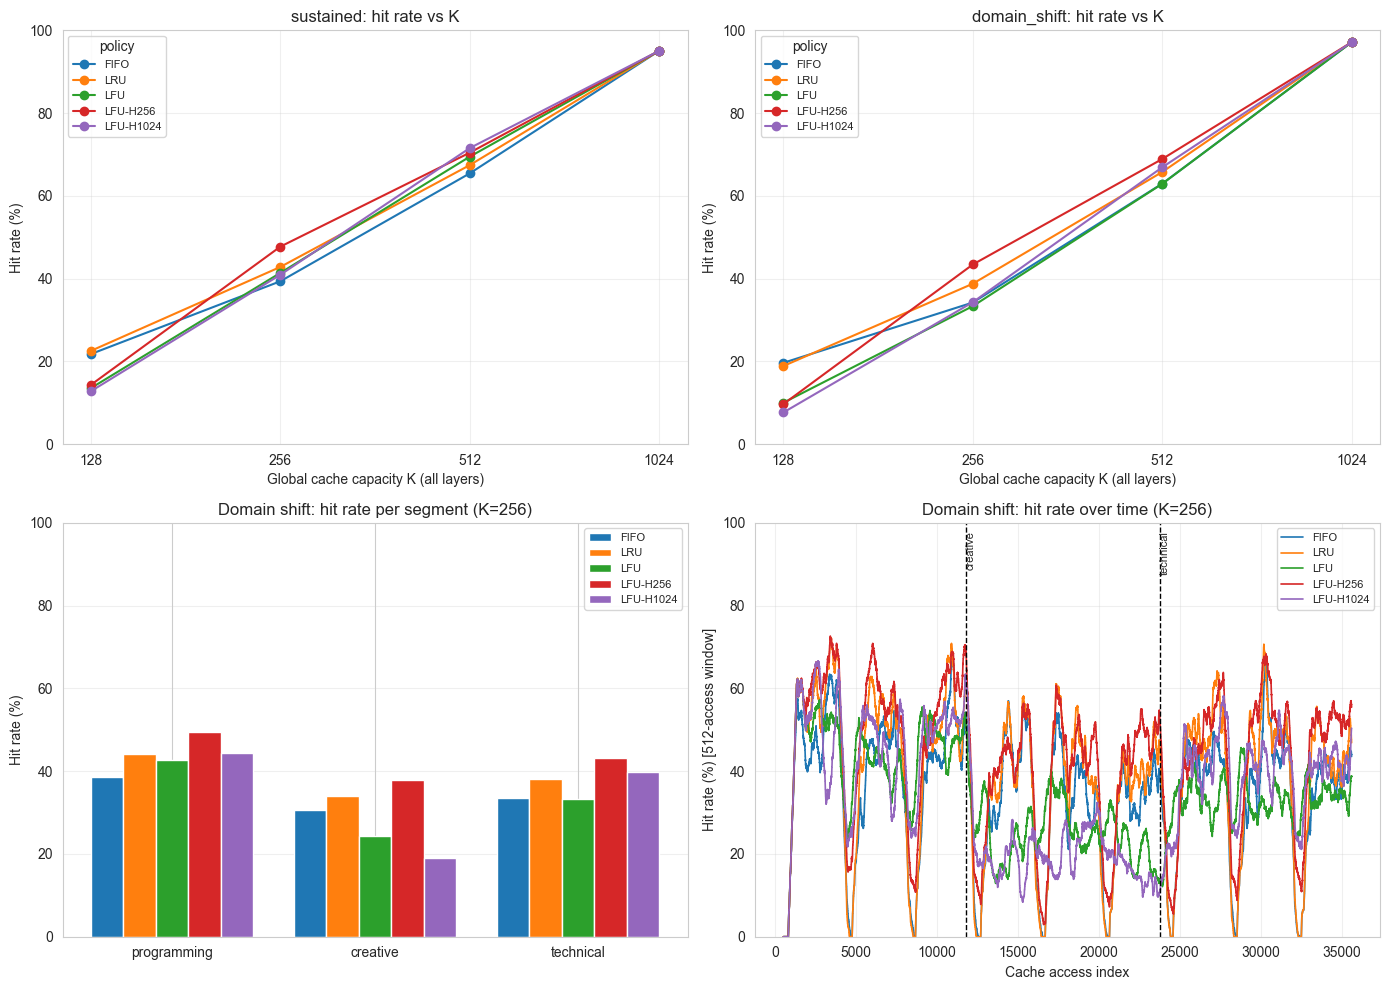

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, wname in zip(axes[0], ['sustained', 'domain_shift']):
    d = df[df.workload == wname]
    for pname in POLICY_CONFIGS:
        s = d[d.policy == pname].sort_values('K')
        ax.plot(s['K'], s['hit_rate'] * 100, marker='o', label=pname)
    ax.set_xscale('log', base=2)
    ax.set_xticks(GLOBAL_K_VALUES)
    ax.set_xticklabels([str(k) for k in GLOBAL_K_VALUES])
    ax.set_xlabel('Global cache capacity K (all layers)')
    ax.set_ylabel('Hit rate (%)')
    ax.set_ylim(0, 100)
    ax.set_title(f'{wname}: hit rate vs K')
    ax.grid(alpha=0.3)
    ax.legend(title='policy', fontsize=8)

# segment-wise, domain shift at K=256
ax = axes[1, 0]
Kbar = 256
d = df[(df.workload == 'domain_shift') & (df.K == Kbar)]
segs = runs[('domain_shift', Kbar, 'LRU')]['segment_order']
width = 0.8 / len(POLICY_CONFIGS)
xpos = np.arange(len(segs))
for i, pname in enumerate(POLICY_CONFIGS):
    vals = [d[d.policy == pname][f'seg_{s}'].iloc[0] * 100 for s in segs]
    ax.bar(xpos + i * width, vals, width, label=pname)
ax.set_xticks(xpos + width * (len(POLICY_CONFIGS) - 1) / 2)
ax.set_xticklabels(segs)
ax.set_ylabel('Hit rate (%)')
ax.set_ylim(0, 100)
ax.set_title(f'Domain shift: hit rate per segment (K={Kbar})')
ax.legend(fontsize=8)
ax.grid(alpha=0.3, axis='y')

# hit rate over time, domain shift at K=256
ax = axes[1, 1]
d = df[(df.workload == 'domain_shift') & (df.K == Kbar)]
for pname in POLICY_CONFIGS:
    rolling = runs[('domain_shift', Kbar, pname)]['rolling']
    ax.plot(np.arange(len(rolling)) + ROLLING_WINDOW - 1, rolling * 100, label=pname, lw=1.2)
segments_by_prompt = streams['domain_shift']['segments']
for seg in runs[('domain_shift', Kbar, 'LRU')]['segment_order'][1:]:
    pid = segments_by_prompt.index(seg)
    boundary = int(np.flatnonzero(streams['domain_shift']['prompts'] == pid)[0])
    ax.axvline(boundary, color='k', ls='--', lw=1)
    ax.text(boundary, 98, seg, rotation=90, va='top', fontsize=8)
ax.set_xlabel('Cache access index')
ax.set_ylabel(f'Hit rate (%) [{ROLLING_WINDOW}-access window]')
ax.set_ylim(0, 100)
ax.set_title(f'Domain shift: hit rate over time (K={Kbar})')
ax.legend(fontsize=8)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

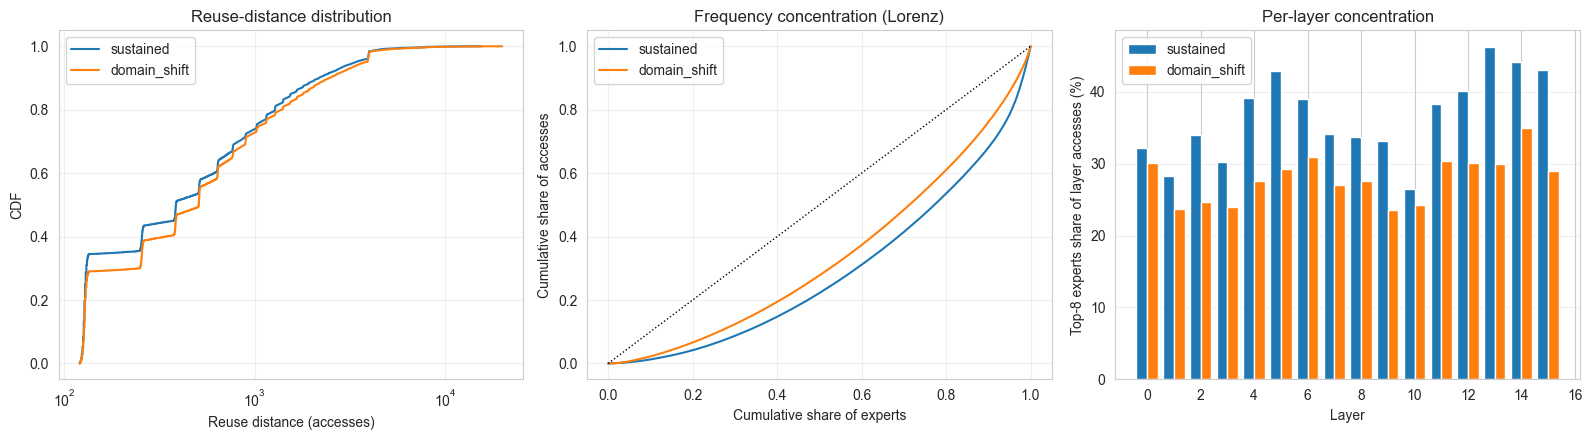

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# reuse-distance CDF
ax = axes[0]
for wname, color in [('sustained', 'C0'), ('domain_shift', 'C1')]:
    r = locality_stats[wname]['reuse']
    r = np.sort(r[np.isfinite(r)])
    ax.plot(r, np.arange(1, len(r) + 1) / len(r), label=wname, color=color)
ax.set_xscale('log')
ax.set_xlabel('Reuse distance (accesses)')
ax.set_ylabel('CDF')
ax.set_title('Reuse-distance distribution')
ax.legend(); ax.grid(alpha=0.3)

# Lorenz curve of expert frequency
ax = axes[1]
for wname, color in [('sustained', 'C0'), ('domain_shift', 'C1')]:
    c = Counter(streams[wname]['keys'])
    f = np.sort(np.array(list(c.values()), dtype=float))
    xs = np.r_[0, np.arange(1, len(f) + 1) / len(f)]
    ys = np.r_[0, np.cumsum(f) / f.sum()]
    ax.plot(xs, ys, label=wname, color=color)
ax.plot([0, 1], [0, 1], 'k:', lw=1)
ax.set_xlabel('Cumulative share of experts')
ax.set_ylabel('Cumulative share of accesses')
ax.set_title('Frequency concentration (Lorenz)')
ax.legend(); ax.grid(alpha=0.3)

# per-layer top-8 share
ax = axes[2]
w = 0.4
for i, (wname, color) in enumerate([('sustained', 'C0'), ('domain_shift', 'C1')]):
    pl = locality_stats[wname]['per_layer']
    ax.bar(pl['layer'] + (i - 0.5) * w, pl['top8_share'] * 100, w, label=wname, color=color)
ax.set_xlabel('Layer')
ax.set_ylabel('Top-8 experts share of layer accesses (%)')
ax.set_title('Per-layer concentration')
ax.legend(); ax.grid(alpha=0.3, axis='y')

plt.tight_layout()
plt.show()

## Step 11 — Hypothesis evaluation

Descriptive checks on the observed traces. The comparison is only as strong as the prompt set;
treat differences of a few points as noise, not proof.

In [15]:
def get(wname, K, pname, col='hit_rate'):
    return float(df[(df.workload == wname) & (df.K == K) & (df.policy == pname)][col].iloc[0])


print('H1 — Does LFU beat LRU on the sustained workload?')
for K in GLOBAL_K_VALUES:
    lfu, lru = get('sustained', K, 'LFU'), get('sustained', K, 'LRU')
    verdict = 'supports' if lfu > lru else 'does not support'
    print(f'  K={K:<5} LFU {lfu:6.1%} vs LRU {lru:6.1%}  '
          f'delta {lfu - lru:+.1%}  -> {verdict}')

print('\nH2 — Does un-decayed LFU fall below LRU after domain shifts?')
for K in [128, 256, 512]:
    lfu, lru = get('domain_shift', K, 'LFU'), get('domain_shift', K, 'LRU')
    print(f'  K={K:<5} overall: LFU {lfu:6.1%} vs LRU {lru:6.1%}  delta {lfu - lru:+.1%}')

for K in [128, 256, 512]:
    print(f'  K={K:<5} post-shift windows:')
    for i, shift in enumerate(['programming -> creative', 'creative -> technical'], start=1):
        try:
            lfu = get('domain_shift', K, 'LFU', f'post_shift_{i}')
            lru = get('domain_shift', K, 'LRU', f'post_shift_{i}')
            dec = get('domain_shift', K, 'LFU-H256', f'post_shift_{i}')
        except IndexError:
            continue
        verdict = 'supports' if lru > lfu else 'does not support'
        print(f'    {shift:25s} LFU {lfu:6.1%} | LRU {lru:6.1%} | '
              f'LFU-H256 {dec:6.1%}  delta(LFU-LRU) {lfu - lru:+.1%} -> {verdict}')

print('\nH2b — hit rate on the first new-domain (creative) segment:')
for K in [128, 256, 512]:
    lfu = get('domain_shift', K, 'LFU', 'seg_creative')
    lru = get('domain_shift', K, 'LRU', 'seg_creative')
    dec = get('domain_shift', K, 'LFU-H256', 'seg_creative')
    verdict = 'supports' if lru > lfu else 'does not support'
    print(f'  K={K:<5} LFU {lfu:6.1%} | LRU {lru:6.1%} | LFU-H256 {dec:6.1%}  '
          f'delta(LFU-LRU) {lfu - lru:+.1%} -> {verdict}')

print('\nDecayed LFU vs un-decayed LFU (domain shift, overall):')
for K in [128, 256, 512]:
    a, b = get('domain_shift', K, 'LFU-H256'), get('domain_shift', K, 'LFU')
    print(f'  K={K:<5} LFU-H256 {a:6.1%} vs LFU {b:6.1%}  delta {a - b:+.1%}')

print('\nFull-bank sanity check (K=1024, no evictions):')
for wname in streams:
    u = len(set(streams[wname]['keys']))
    n = len(streams[wname]['keys'])
    print(f'  {wname}: hit rate {get(wname, 1024, "LRU"):.1%} vs theoretical '
          f'{1 - u / n:.1%} (1 - distinct/accesses)')

print('\nSanity control (synthetic streams, K=16) — checks the policy implementations, '
      'not the model:')
rng = np.random.default_rng(1)
p = 1.0 / np.arange(1, 65)
p /= p.sum()
zipf = rng.choice(64, size=20000, p=p)
shift = zipf.copy()
shift[10000:] = np.where(rng.random(10000) < 0.8,
                         rng.integers(8, 16, 10000), rng.integers(16, 64, 10000))


def _rate(policy, seq):
    for k in seq:
        policy.access(int(k))
    return policy.hits / len(seq)


print(f'  stationary Zipf: LFU {_rate(LFUPolicy(16), zipf):.1%} vs '
      f'LRU {_rate(LRUPolicy(16), zipf):.1%}   (LFU should win)')
print(f'  phase shift:     LFU {_rate(LFUPolicy(16), shift):.1%} vs '
      f'LRU {_rate(LRUPolicy(16), shift):.1%} vs '
      f'LFU-H512 {_rate(LFUPolicy(16, 512), shift):.1%}   '
      f'(un-decayed LFU should collapse)')

H1 — Does LFU beat LRU on the sustained workload?
  K=128   LFU  13.6% vs LRU  22.6%  delta -9.0%  -> does not support
  K=256   LFU  41.4% vs LRU  42.8%  delta -1.4%  -> does not support
  K=512   LFU  69.5% vs LRU  67.4%  delta +2.0%  -> supports
  K=1024  LFU  95.1% vs LRU  95.1%  delta +0.0%  -> does not support

H2 — Does un-decayed LFU fall below LRU after domain shifts?
  K=128   overall: LFU  10.0% vs LRU  18.9%  delta -8.9%
  K=256   overall: LFU  33.4% vs LRU  38.8%  delta -5.4%
  K=512   overall: LFU  62.9% vs LRU  65.8%  delta -2.9%
  K=128   post-shift windows:
    programming -> creative   LFU   4.9% | LRU  16.1% | LFU-H256   1.7%  delta(LFU-LRU) -11.1% -> supports
    creative -> technical     LFU  10.0% | LRU  18.5% | LFU-H256   5.8%  delta(LFU-LRU) -8.4% -> supports
  K=256   post-shift windows:
    programming -> creative   LFU  21.6% | LRU  39.1% | LFU-H256  39.3%  delta(LFU-LRU) -17.5% -> supports
    creative -> technical     LFU  35.9% | LRU  44.0% | LFU-H256  42.

## Reading these results

In the default configuration:

- At small `K`, un-decayed LFU is the *worst* policy: keys admitted during early prefill
  saturate the cache and new keys are evicted before they can accumulate frequency
  (cold-start pollution). The synthetic control shows the same implementation winning on
  stationary traffic, so this is a property of routing, not a bug.
- As `K` grows, the gap narrows and un-decayed LFU can edge ahead on the sustained workload.
- H2 shows up most clearly in the per-segment table and the new-domain decode window: the
  creative segment loses about 10 points under un-decayed LFU at every `K`.
- Decayed LFU recovers the useful part of the frequency signal: it is the best overall policy
  at `K=256` and `K=512` on the domain-shift workload, and it matches or beats LRU in the new
  domain at those capacities.
- At `K=1024` every policy degenerates to compulsory misses, confirming that the simulated
  cache state is exactly the reachable working set.

The first 512 decode accesses after a shift can look kind on LFU (pinned experts still overlap
with the new domain), which is why the window is widened to ~16 generated tokens and why the
segment-level number is the primary H2 test.

## Limitations & next steps

* **Prompt set is small.** Ten prompts define the whole workload. Domain shifts are simulated at
  prompt boundaries, not by an actual multi-turn conversation, so H2 is tested structurally
  rather than conversationally.
* **Call-level accesses.** Distinct experts are counted once per MoE call, matching a real
  layer's fetch pattern. Policies that reward within-batch reuse are not modelled; they would
  only inflate hit rates uniformly.
* **No I/O latency in the comparison.** The metrics are hit rate and evictions. Real latency also
  depends on SSD throughput, prefetching, and whether the loader overlaps compute (the tracing
  cache does not overlap; it is a correctness-first loader).
* **Per-layer residency is only implicit.** Global `K` does not force `K/16` per layer; one layer
  can hold more. If per-layer quotas matter, add a per-layer cap and rerun the replay.
* **LFU decay is per access, not per token or per second.** Half-life values are workloads with
  different throughputs; normalize before deployment.

**Next steps**

1. Scale to a larger, domain-labelled prompt set (and real multi-turn conversations).
2. Add a per-layer residency cap alongside global `K`.
3. Overlap expert loading with compute (prefetch the next layer's likely experts) and measure
   end-to-end latency, not just hit rate.
4. Compare against a frequency oracle (static top-K experts) to see how much online adaptation
   is worth.